# 07 · Risk rules for a portfolio

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/07_portfolio_risk_rules.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

In notebook 03 one fund (SPY) had limits and three ways to react to a crash. Now a **portfolio** gets the same treatment: five big tech funds and shares, a list of calm assets to move into, and a fourth reaction, **rotate**. This notebook also asks *what drove that fall?* and *what if?*, and it sets up the gate that the AI agent in notebook 09 must pass.

**What you'll do (~60 min):**
1. Turn an investor's limits into warning lines (a recap of notebook 03)
2. Estimate a bad day for a portfolio with **value at risk** and **expected shortfall**
3. Compare four reactions to a crash: **hold**, **sell and stay out**, **sell and come back**, **rotate**
4. Ask *what drove that fall?* with the market split
5. Ask *what if?* with a shock

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

## Setup

Run this cell first. In Google Colab it downloads the workshop code and price data from GitHub; on a laptop it simply finds them.

In [1]:
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)

## 1. Limits and warning lines, again

Notebook 03 turned an investor's sentence into numbers. Here is the same idea for a portfolio:

> *"Never let my portfolio fall more than **15%** from its peak, and never lose more than **3%** in a single day."*

| Line | Value | What happens |
|---|---|---|
| Rotate | half the drawdown limit (7.5%) | move some risk into calmer assets |
| Emergency | 80% of the drawdown limit (12%) | cut risk hard |
| VaR budget | the daily limit (3%) | keep a likely bad day within the limit |

In [2]:
from backtester import load_closes, risk

limits = risk.Limits(max_drawdown=0.15, max_daily_loss=0.03)
risk.lines_from_limits(limits)

Lines(rotate_at=0.075, emergency_at=0.12, var_budget=0.03, shock_day=0.03)

Now a portfolio a student might really own: **five big tech holdings in equal parts**. We give it a list of **calm** assets it may move money into: long and medium government bonds, gold, and three steady sectors (consumer staples, utilities, healthcare).

In [3]:
TECH = ["AAPL", "MSFT", "AMZN", "GOOGL", "QQQ"]
CALM = ["TLT", "IEF", "GLD", "XLP", "XLU", "XLV"]
prices = load_closes(TECH + CALM, start="2019-06-01", end="2023-12-31").dropna()
start = {t: 0.2 for t in TECH}


## 2. How bad is a bad day for this portfolio?

The same three numbers as notebook 03, on the same days, for the tech portfolio: the 99% one-day value at risk from the formula, the same read from history, and the average loss on the worst 1% of days (expected shortfall).

In [4]:
tech_returns = (prices[TECH].pct_change() * 0.2).sum(axis=1).iloc[1:]
pd.Series({
    "99% one-day VaR from the formula": risk.one_day_var(pd.Series(start), prices.pct_change(), lookback=len(prices)),
    "99% one-day VaR read from history": risk.historical_var(tech_returns),
    "Average loss on the worst 1% of days": risk.expected_shortfall(tech_returns),
}).map("{:.2%}".format).to_frame("Tech portfolio")

,Tech portfolio
99% one-day VaR from the formula,4.12%
99% one-day VaR read from history,4.55%
Average loss on the worst 1% of days,6.31%


**An honest reading.** On a normal day the portfolio is fine. But on about one day in a hundred it should lose more than **4.1%** (formula) or **4.6%** (read from history), and on those worst days the average loss is **6.3%**. The investor's daily limit is only 3%.

So a fully invested tech portfolio cannot honestly promise to stay inside this limit. That is why the rules below act before any crash: they look at the one-day VaR every day, and they start moving money as soon as it passes the 3% budget. The history figure is a little higher than the formula because real markets have fatter tails than the bell curve in the formula.

## 3. Four ways to react to a crash

We replay 2019 to 2023 day by day. On each close the code checks the lines. When one is crossed, a **risk manager** decides what to do. Cash earns 3% a year in every run, as in notebook 03.

1. **Buy and hold:** do nothing, ever.
2. **Sell and stay out:** on the first real loss past a line, sell everything and stay in cash for good.
3. **Sell and come back:** the same sale, but buy the portfolio back after 60 trading days in cash.
4. **Rotate:** move 5% at a time from the holding causing the most risk into the calmest candidate, until the VaR is within budget. After 10 quiet days, step 5% back towards the original portfolio.

Every proposal must pass `check_plan`, a fixed test: only allowed tickers, no holding above 40%, steps of 5%, VaR within budget. Remember this gate: in notebook 09 an AI model has to pass exactly the same one.

*(This cell replays about 1,100 days four times; give it 30 seconds.)*

In [5]:
hold = risk.run_guarded(prices, start, limits, manager=None, calm=CALM, name="Buy and hold", cash_rate=0.03)
stay_out = risk.run_guarded(prices, start, limits, manager=risk.cash_exit_manager, calm=CALM, name="Sell and stay out", cash_rate=0.03)
come_back = risk.run_guarded(prices, start, limits, manager=risk.exit_and_return_manager, calm=CALM, name="Sell and come back", cash_rate=0.03)
rotate = risk.run_guarded(prices, start, limits, manager=risk.rotate_manager, calm=CALM, name="Rotate (rules)", cash_rate=0.03)
risk.compare([hold, stay_out, come_back, rotate])

,Buy and hold,Sell and stay out,Sell and come back,Rotate (rules)
Total return,163.3%,41.0%,99.2%,97.2%
Annual return (CAGR),25.0%,8.2%,17.2%,16.9%
Annual volatility,28.3%,5.3%,15.4%,17.4%
Sharpe ratio,0.83,0.97,0.92,0.82
Max drawdown,-37.2%,-7.6%,-18.0%,-28.3%
Number of trades,0,1,17,77
Days over daily limit,45,1,12,12
Worst day,-11.5%,-4.3%,-5.9%,-5.8%
Costs paid,0.0%,0.0%,0.8%,0.6%


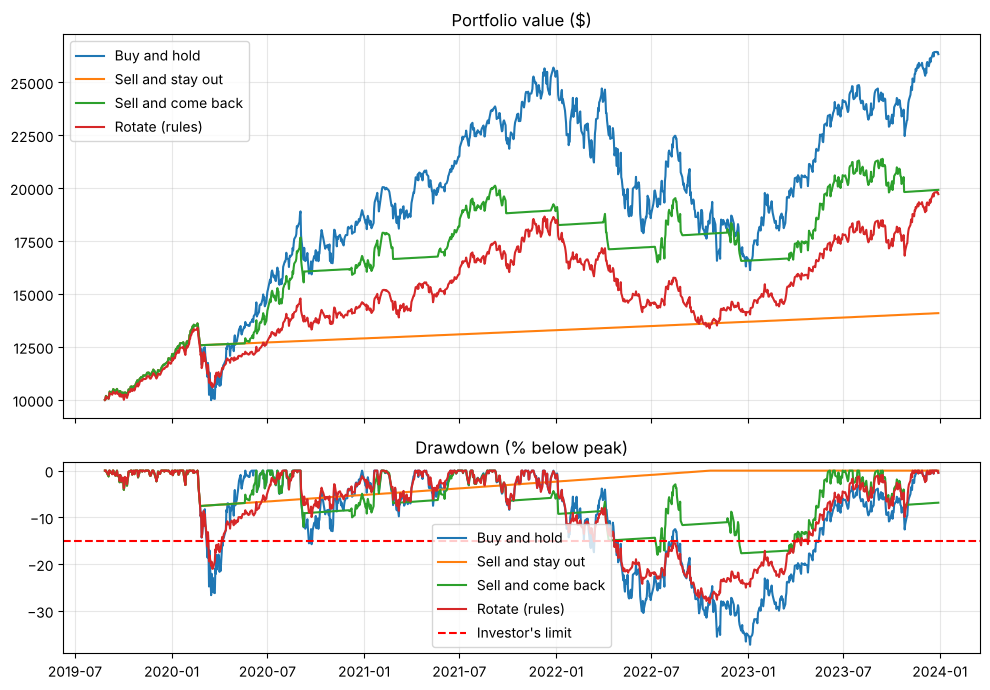

In [6]:
from backtester.metrics import drawdown_series

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for result in (hold, stay_out, come_back, rotate):
    top.plot(result.equity.index, result.equity, label=result.name)
    bottom.plot(result.equity.index, drawdown_series(result.equity) * 100, label=result.name)
bottom.axhline(-limits.max_drawdown * 100, color="red", linestyle="--", label="Investor's limit")
top.set_title("Portfolio value ($)"); bottom.set_title("Drawdown (% below peak)")
top.legend(); bottom.legend(); top.grid(alpha=0.3); bottom.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the saved run shows.**

- **Buy and hold** made the most (163%) but fell as far as -37% and broke the daily limit on 45 days.
- **Sell and stay out** sold once and never returned. Its fall was only -8%, but it made 41%, because it missed the whole recovery. Its good Sharpe ratio comes from sitting in cash that pays 3%, not from skill.
- **Sell and come back** made 99% with a fall of -18%, at the price of 17 trades and 0.8% in costs.
- **Rotate** made 97% with a fall of -28%. Its Sharpe ratio (0.82) is about the same as buy and hold (0.83): it took less risk and earned proportionally less.

No reaction wins on everything. Sell-and-come-back looks best on risk against reward here, but its result depends heavily on one setting, the length of the wait. The next cell changes only that.

### How much does one setting matter?

Same crash, same rules, only the wait before buying back changes:

In [7]:
rows = {}
for days in (20, 60, 120, 250):
    risk.STAY_OUT_DAYS = days
    run = risk.run_guarded(prices, start, limits, manager=risk.exit_and_return_manager, calm=CALM, name=f"{days} days", cash_rate=0.03)
    rows[f"Back after {days} days"] = run.metrics
risk.STAY_OUT_DAYS = 60
table = pd.DataFrame(rows).loc[["Total return", "Annual return (CAGR)", "Sharpe ratio", "Max drawdown"]]
table.apply(lambda row: row.map("{:.2f}".format if row.name == "Sharpe ratio" else "{:.1%}".format), axis=1)

,Back after 20 days,Back after 60 days,Back after 120 days,Back after 250 days
Total return,226.4%,99.2%,69.1%,53.2%
Annual return (CAGR),31.4%,17.2%,12.9%,10.3%
Sharpe ratio,1.23,0.92,0.79,0.67
Max drawdown,-18.7%,-18.0%,-15.8%,-15.6%


Waiting 20 days gave a Sharpe ratio of about 1.2 and waiting 250 days gave about 0.7, from the same data and the same rules. The short wait wins only because the 2020 crash recovered in weeks. A student who picks "20 days" after seeing this table has tuned a setting to the past, which is the trap from notebook 02. A fair test would choose the wait on one period and score it on another.

### Inside the crises

In [8]:
risk.crisis_table({r.name: r.equity for r in (hold, stay_out, come_back, rotate)})

Return Worst fall
Crisis           Portfolio                            
2020 Covid crash Buy and hold         26.2%     -26.6%
                 Sell and stay out    -6.2%      -7.6%
                 Sell and come back   18.1%      -7.6%
                 Rotate (rules)        4.7%     -21.0%
2022 bear market Buy and hold        -34.5%     -36.2%
                 Sell and stay out     3.0%       0.0%
                 Sell and come back  -13.3%     -15.2%
                 Rotate (rules)      -23.6%     -27.7%

### Every decision, with its reason

The log shows what the rules saw and what they did. This is what an investor should be able to read.

In [9]:
rotate.log[["date", "trigger", "reasons", "action", "turnover"]].head(12)

,date,trigger,reasons,action,turnover
0,2019-08-27,rotate,One-day VaR 3.07% is above the 3.00% budget.,rotate,0.3000
1,2019-09-11,NaN,Quiet for 10 days.,re-risk 5%,0.0911
2,2019-09-25,NaN,Quiet for 10 days.,re-risk 5%,0.1085
3,2019-10-29,NaN,Quiet for 10 days.,re-risk 5%,0.1229
4,2020-02-24,rotate,Drawdown -7.5% is past the rotate line of -7.5%. Today's loss of -4.3% is beyond the daily limit of -3.0%.,rotate,0.0351
5,2020-03-03,rotate,Drawdown -11.8% is past the rotate line of -7.5%. Today's loss of -3.4% is beyond the daily limit of -3.0%. One-day ...,rotate,0.5051
6,2020-03-11,emergency,Drawdown -16.1% is past the emergency line of -12.0%.,rotate,0.8756
7,2020-03-26,NaN,Quiet for 10 days.,re-risk 5%,0.1192
8,2020-04-06,rotate,One-day VaR 3.20% is above the 3.00% budget.,rotate,0.2037
9,2020-05-27,NaN,Quiet for 10 days.,re-risk 5%,0.1037


## 4. What drove a bad day: the market, or my holdings?

The **CAPM** split from the take-home project: a portfolio's move is partly the whole market (**beta** x the market's move) and partly down to its own holdings. Beta is estimated only from the six months **before** the day, so there is no look-ahead.

In [10]:
spy = load_closes(["SPY"], start="2019-06-01", end="2023-12-31")["SPY"].pct_change()
tech_daily = (prices[TECH].pct_change() * 0.2).sum(axis=1)
worst_day = tech_daily.loc["2020"].idxmin()
split = risk.capm_split(tech_daily, spy, worst_day)
print(f"Worst day of 2020: {worst_day:%Y-%m-%d}")
pd.Series({
    "Beta (how strongly it follows the market)": f"{split['beta']:.2f}",
    "Portfolio's move that day": f"{split['total']:.2%}",
    "Explained by the market": f"{split['market_part']:.2%}",
    "Down to our own holdings": f"{split['own_part']:.2%}",
}).to_frame(f"{worst_day:%Y-%m-%d}")

Worst day of 2020: 2020-03-16


,2020-03-16
Beta (how strongly it follows the market),1.05
Portfolio's move that day,-11.32%
Explained by the market,-11.50%
Down to our own holdings,0.18%


In [11]:
risk.unusual_moves(prices.pct_change(), worst_day).round(3)

,return,z_score,spike_ratio
XLU,-0.114,-4.883,2.297
QQQ,-0.120,-4.546,2.256
XLV,-0.099,-4.470,2.229
MSFT,-0.147,-4.413,2.260
GOOGL,-0.116,-4.279,2.100
AAPL,-0.129,-3.795,2.174
XLP,-0.068,-2.903,2.373
AMZN,-0.054,-2.124,1.896
GLD,-0.011,-1.035,1.985
TLT,0.065,4.387,1.931


A **z-score** below -3 means the move was far outside its usual range. A **spike ratio** above 1.5 means volatility has jumped recently. Notebook 09 uses these to decide when the AI model is worth asking at all.

## 5. What if?

Take an ordinary day and pretend some holdings crashed. `what_if` rewrites that one day; `decide_on` shows what the lines and the manager would do.

In [12]:
DAY = "2021-06-15"
shocked = risk.what_if(prices, DAY, {"AAPL": -0.12, "MSFT": -0.10, "QQQ": -0.08})
decision = risk.decide_on(shocked, start, DAY, limits, calm=CALM)
print("Trigger:", decision["trigger"], "|", " ".join(decision["reasons"]))
print("Plan:", decision["plan"])
print("Passes the check:", decision["check"].passed if decision["check"] else "no plan")

Trigger: rotate | Today's loss of -6.2% is beyond the daily limit of -3.0%. One-day VaR 3.25% is above the 3.00% budget.
Plan: {'AAPL': 0.15, 'MSFT': 0.15, 'AMZN': 0.2, 'GOOGL': 0.2, 'QQQ': 0.15, 'IEF': 0.15}
Passes the check: True


## 6. ✏️ Your turn

Change the cells above, or the one below, and re-run:
- Tighten the limits to 10% and 2%. What happens to the number of trades and the costs?
- Remove the bonds from `CALM`. Does rotating still help in 2022?
- Write your own manager: a function that takes `context` and returns a dict of weights (or `None` to hold). Look at `context.keys()` to see what it can use.

In [13]:
def my_manager(context):
    if context["trigger"] is None:
        return None
    return {"QQQ": 0.4, "TLT": 0.3, "GLD": 0.3}

mine = risk.run_guarded(prices, start, limits, manager=my_manager, calm=CALM, name="My manager", cash_rate=0.03)
risk.compare([hold, rotate, mine])

,Buy and hold,Rotate (rules),My manager
Total return,163.3%,97.2%,70.2%
Annual return (CAGR),25.0%,16.9%,13.0%
Annual volatility,28.3%,17.4%,15.3%
Sharpe ratio,0.83,0.82,0.68
Max drawdown,-37.2%,-28.3%,-29.3%
Number of trades,0,77,82
Days over daily limit,45,12,8
Worst day,-11.5%,-5.8%,-4.7%
Costs paid,0.0%,0.6%,0.7%


**Questions to discuss:**
- Is a lower return with a smaller fall a better portfolio? For whom?
- Which assets are truly "calm"? Were they calm in 2022?
- Our rules were tuned by looking at 2020 and 2022. How would you test them fairly? (Notebook 02 has the tools.)

### Next: is the result real?

Alpha, beta and the t-stat: how much of a return is just the market, and how much could be luck?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/08_alpha_beta_competition.ipynb) `08_alpha_beta_competition.ipynb`